# Module 6 — Transformers and Attention Mechanisms

## Lesson 6.3 — Understanding Attention


In Note 6.1 we said that attention is the only place in a Transformer where tokens exchange information, and we saw it work as part of a complete model. In Note 5.4 we built a tiny one-step version of it and found that its learning signal does not fade with distance. Now it is time to open it up completely.

Attention is the single most important idea in modern AI, and it is less mysterious than its reputation suggests. At its core it is three steps: compare, normalise, average. Every token **compares** itself with the others to decide who is relevant, turns those comparisons into **weights** that add up to one, and takes a **weighted average** of what the relevant tokens have to offer. Everything else in this note (queries, keys, values, scaling, masks and heads) is a refinement of those three steps.

We will work through attention by hand on tiny examples, so that every number is visible, then build a full multi-head causal self-attention module and check it against PyTorch's own implementation.

**Key question:** *How does attention let each token gather information from the others?*

### Learning objectives
- explain why tokens need to exchange information, and what queries, keys and values are;
- compute attention scores, weights and outputs by hand;
- explain why scores are divided by √d before softmax, with evidence;
- apply a causal mask and explain what it does;
- explain multi-head attention and why attention needs positional information;
- estimate how the cost of attention grows with sequence length;
- implement multi-head causal self-attention in PyTorch.

### Prerequisites

 read Notes 6.1 and 6.2. You will need matrix multiplication, softmax and the `(batch, tokens, d_model)` shape convention.

### Setup

Run this cell first. This note uses no dataset and trains nothing; every example is small enough to run instantly.

**Environment and results.** The saved outputs record one CPU reference run; random seeds reduce variation but do not guarantee identical numbers across computers. Read the comparisons as evidence from that run. Training times depend on your hardware.

If packages are missing, install them into your notebook environment, then restart the kernel and run from the beginning:

```text
%pip install torch==2.14.1 numpy==2.5.4 pandas==3.0.6 matplotlib==3.11.2 scikit-learn==1.9.1 scipy==1.18.1
```

In [1]:
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


## 1. The Big Picture: How Attention Helps a Model Focus on Relevant Information

Imagine reading the sentence *"The animal didn't cross the street because it was too tired."* To understand "it", you look back over the sentence and decide that "animal" is the relevant word, not "street". If the sentence ended "...because it was too wide", you would pick "street" instead. Understanding a word means **gathering information from the right other words**, and which words are right depends on the context.

Attention gives every token a way to do exactly that. For each token, it works out how relevant every other token is, then builds a new vector for the token from a relevance-weighted mix of the others. The token's new vector now carries context.

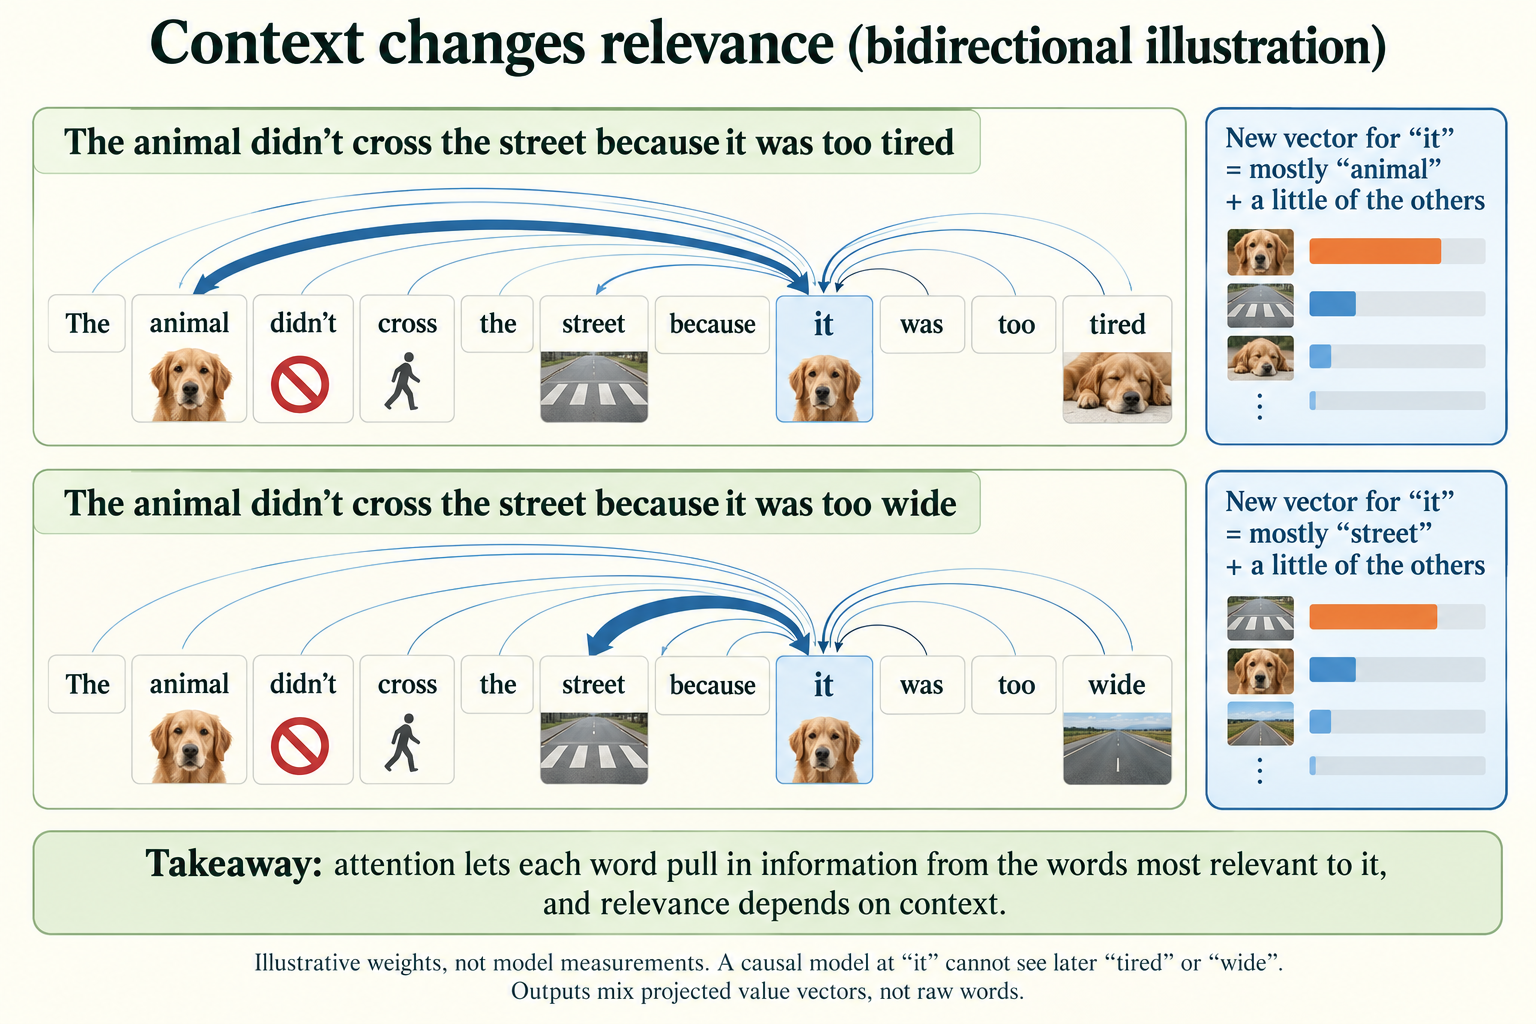

*Figure 6.3.1. Bidirectional illustration with invented attention weights. Later tired or wide can affect an earlier position only when the mask permits it. A causal model at it cannot see those future words. Attention mixes projected values and is not a guaranteed explanation of a decision.*

The rest of this note explains how a network computes "how relevant", and how it uses the answer.

## 2. The Limitations of Processing Tokens Independently

First, let's see precisely why we need a mechanism like this. Most layers you know, such as linear layers, activation functions and the feed-forward network inside a Transformer block, process each token's vector **on its own**. Whatever the surrounding tokens are, the same input vector produces the same output vector.

Here is the word "bank" in two sentences, "the river bank" and "money in the bank", passed through such a per-token layer:

In [2]:
torch.manual_seed(0)
vocab = {"the": 0, "river": 1, "bank": 2, "money": 3, "in": 4}
emb = nn.Embedding(len(vocab), 8)
per_token = nn.Linear(8, 8)                    # a layer that looks at each token on its own
s1 = torch.tensor([vocab[w] for w in ["the", "river", "bank"]])
s2 = torch.tensor([vocab[w] for w in ["money", "in", "the", "bank"]])
with torch.no_grad():
    out1, out2 = per_token(emb(s1)), per_token(emb(s2))
print("'bank' after a per-token layer, sentence 1:", [round(v, 3) for v in out1[2, :4].tolist()], "...")
print("'bank' after a per-token layer, sentence 2:", [round(v, 3) for v in out2[3, :4].tolist()], "...")
print("identical?", torch.equal(out1[2], out2[3]))

'bank' after a per-token layer, sentence 1: [0.375, -0.637, -0.336, -0.195] ...
'bank' after a per-token layer, sentence 2: [0.375, -0.637, -0.336, -0.195] ...
identical? True


The two outputs for "bank" are identical (`True`). However many per-token layers we stack, "bank" by the river and "bank" with the money will always be processed identically, because no information ever flows between positions. This is the static-representation problem from Note 5.3, seen from inside a network.

To build context, tokens must be able to **read from each other**. That is the one job of attention.

## 3. Self-Attention: The Complete Picture

Here is the whole mechanism for a sequence of T tokens, each represented by a vector. We call it **self-attention** because the tokens attend to other tokens of the *same* sequence.

1. **Project.** From each token's vector, compute three new vectors with three different learned linear layers: a **query** q, a **key** k and a **value** v.
2. **Score.** For every pair of tokens (i, j), compute a relevance score: the dot product of token i's query with token j's key.
3. **Scale.** Divide every score by √d, where d is the length of the query and key vectors.
4. **Mask** (decoders only). Block the scores for pairs that are not allowed, such as future tokens.
5. **Normalise.** Apply softmax across each row, so that each token's weights over all the tokens are positive and add up to 1.
6. **Mix.** Each token's output is the weighted average of all the value vectors, using its weights.

Written compactly, with the queries, keys and values for all tokens stacked as rows of matrices Q, K and V:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}}\right) V$$

Don't worry if the formula looks dense: Sections 4 to 8 take it apart one step at a time, with numbers you can check by hand.

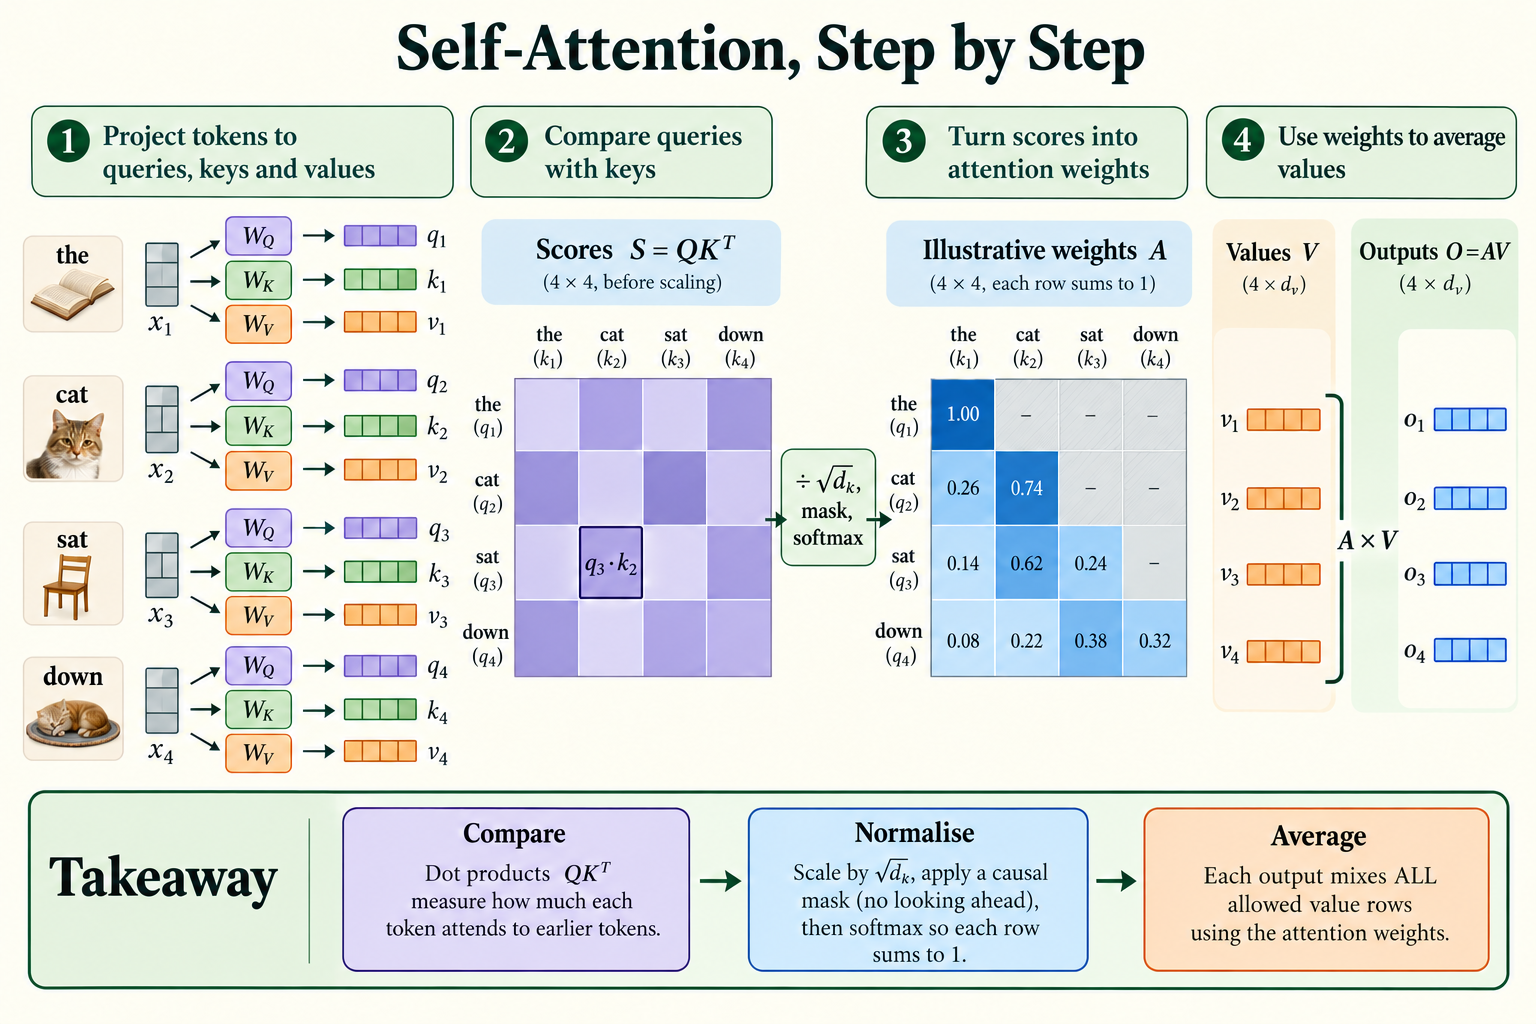

*Figure 6.3.2. Project Q, K and V; compare queries with keys; scale by √dₖ; apply the mask before row-wise softmax; then mix values. Each output is a weighted sum of projected value vectors.*

## 4. Queries, Keys, and Values: An Intuitive Introduction

Why three different vectors per token? Think of a library search.

- The **query** is what you are looking for: the search you type.
- Each book has a **key**: the label or catalogue entry that describes it, used only for matching.
- Each book also has its **value**: the actual content you take away once you decide it is relevant.

Matching uses queries against keys; what you collect is values. Separating them lets a token *look for* one thing while *offering* something different. For example, a verb might look for its subject (its query), describe itself as an action (its key), and pass on information about tense (its value).

In a Transformer, all three are produced by learned linear layers from the token's vector, so the network learns what to look for, how to describe itself and what to pass on. To keep the arithmetic visible, we will use a hand-made example with 4 tokens, "the cat sat down", and query, key and value vectors of just 2 numbers each. The numbers are chosen so that "sat" and "down" look for something that "cat" offers, as a verb might look for its subject.

## 5. Computing Attention Scores

The score between token i and token j is the dot product of i's query with j's key: multiply matching entries and add. A large score means "j's key matches what i is looking for". We compute all 16 scores with two loops, then check against the single matrix product Q Kᵀ.

In [3]:
tokens = ["the", "cat", "sat", "down"]
#                 the        cat        sat        down
Q = torch.tensor([[0.0, 1.0], [0.0, 1.0], [2.0, 0.0], [2.0, 0.5]])   # what each token is looking for
K = torch.tensor([[0.0, 1.0], [2.0, 0.0], [0.5, 0.5], [0.0, 0.5]])   # what each token offers as a label
V = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0], [0.5, 0.5]])   # what each token passes on
d_k = Q.shape[1]
scores_by_hand = torch.zeros(4, 4)
for i in range(4):
    for j in range(4):
        scores_by_hand[i, j] = (Q[i] * K[j]).sum()        # dot product of query i with key j
print("scores by hand:\n", scores_by_hand)
print("same as Q @ K.T?", torch.equal(scores_by_hand, Q @ K.T))

scores by hand:
 tensor([[1.0000, 0.0000, 0.5000, 0.5000],
        [1.0000, 0.0000, 0.5000, 0.5000],
        [0.0000, 4.0000, 1.0000, 0.0000],
        [0.5000, 4.0000, 1.2500, 0.2500]])
same as Q @ K.T? True


Read the score grid row by row; each row is one token asking "who is relevant to me?".

- The row for "sat" is `[0, 4, 1, 0]`. Its query `[2, 0]` matches the key of "cat", `[2, 0]`, strongly: 2 × 2 + 0 × 0 = 4. The other keys match much less.
- The row for "down" is similar, `[0.5, 4, 1.25, 0.25]`: it is also most interested in "cat".
- "the" and "cat" share the query `[0, 1]`, so their rows are identical: `[1, 0, 0.5, 0.5]`.

The loops and `Q @ K.T` give exactly the same grid (`True`). In practice we always use the matrix product: one operation computes every score at once, which is exactly the parallelism that makes Transformers fast.

**Check yourself.**

1. A query is `[1, 2]` and a key is `[3, −1]`. What is their score?

<details>
<summary>Worked answer</summary>

1 × 3 + 2 × (−1) = 3 − 2 = 1.

</details>

## 6. Scaling and Softmax

Scores can be any size, but we want **weights**: positive numbers that add up to 1 for each token, so that each token divides 100% of its attention among the others. Softmax does exactly that. But before softmax, the scores are divided by √d. Why?

### 6.1 Why divide by √d

A dot product adds up d products. If the entries of queries and keys are random numbers with a typical size of about 1, then the more numbers you add, the larger the typical result: its spread grows like √d. Let's measure that with 10,000 random query–key pairs.

In [4]:
for d in [4, 64, 512]:
    q, k = torch.randn(10000, d), torch.randn(10000, d)
    dots = (q * k).sum(1)
    print(f"d = {d:>3}: std of raw dot products {dots.std():6.2f} | after dividing by sqrt(d) {(dots / math.sqrt(d)).std():.2f}")

d =   4: std of raw dot products   1.99 | after dividing by sqrt(d) 1.00
d =  64: std of raw dot products   8.01 | after dividing by sqrt(d) 1.00
d = 512: std of raw dot products  22.45 | after dividing by sqrt(d) 0.99


The spread (standard deviation) of the raw dot products is 1.99 for d = 4, 8.01 for d = 64 and 22.45 for d = 512, growing like √d (√4 = 2, √64 = 8, √512 ≈ 22.6). After dividing by √d, it is 1.00, 1.00 and 0.99: the same at every size.

Why does the size of the scores matter? Because softmax exaggerates differences. If scores are large, the largest one swallows almost all the weight. Here are 8 scores with d = 512, passed through softmax with and without scaling:

In [5]:
torch.manual_seed(1)
d = 512
q, k = torch.randn(d), torch.randn(8, d)
raw = k @ q
for name, s in [("without scaling", raw), ("divided by sqrt(d)", raw / math.sqrt(d))]:
    w = torch.softmax(s, dim=0)
    ent = -(w * w.clamp_min(1e-12).log()).sum().item()
    print(f"{name:<20} largest weight {w.max():.3f} | entropy {ent:.3f} (max possible {math.log(8):.3f})")
print("weights without scaling:", [round(v, 3) for v in torch.softmax(raw, 0).tolist()])
print("weights with scaling:   ", [round(v, 3) for v in torch.softmax(raw / math.sqrt(d), 0).tolist()])

without scaling      largest weight 1.000 | entropy 0.000 (max possible 2.079)
divided by sqrt(d)   largest weight 0.442 | entropy 1.480 (max possible 2.079)
weights without scaling: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0]
weights with scaling:    [0.016, 0.166, 0.021, 0.259, 0.032, 0.019, 0.043, 0.442]


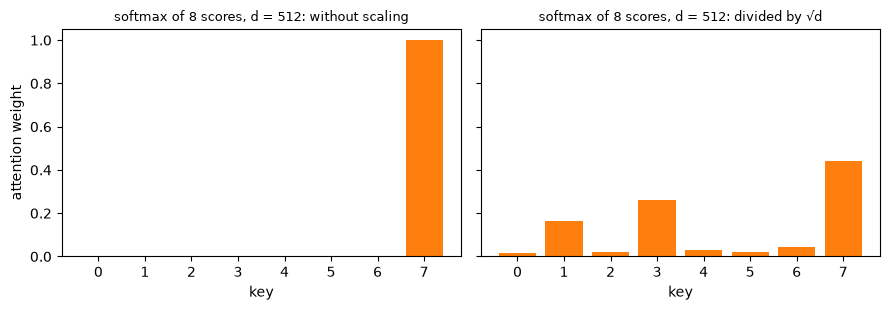

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (name, s) in zip(axes, [("without scaling", raw), ("divided by √d", raw / math.sqrt(d))]):
    ax.bar(range(8), torch.softmax(s, 0).numpy(), color="tab:orange")
    ax.set_title(f"softmax of 8 scores, d = {d}: {name}", fontsize=9); ax.set_xlabel("key"); ax.set_ylim(0, 1.05)
axes[0].set_ylabel("attention weight"); plt.tight_layout(); plt.show()

Without scaling, softmax puts a weight of 1.000 on a single key and 0.0 on the other seven: the entropy is 0.000, which means no uncertainty and no blending at all. With scaling, the largest weight is 0.442 and the rest is shared among several keys, with an entropy of 1.480 (the maximum possible for 8 keys is 2.079).

This matters for **learning**, not just for the output. When softmax is that extreme, small changes to the scores barely change the weights, so the gradients flowing back through the softmax are close to zero, and the queries and keys stop learning. Dividing by √d keeps scores at a sensible size however wide the vectors are, so attention can stay soft and trainable.

### 6.2 Softmax in our example

Now we apply both steps to the "the cat sat down" scores. Here d = 2, so we divide by √2 ≈ 1.414.

In [7]:
scores = Q @ K.T / math.sqrt(d_k)
weights = torch.softmax(scores, dim=-1)             # each ROW sums to 1
print("scaled scores:\n", scores.round(decimals=3))
print("attention weights:\n", weights.round(decimals=3))
print("row sums:", weights.sum(-1).tolist())

scaled scores:
 tensor([[0.7070, 0.0000, 0.3540, 0.3540],
        [0.7070, 0.0000, 0.3540, 0.3540],
        [0.0000, 2.8280, 0.7070, 0.0000],
        [0.3540, 2.8280, 0.8840, 0.1770]])
attention weights:
 tensor([[0.3450, 0.1700, 0.2420, 0.2420],
        [0.3450, 0.1700, 0.2420, 0.2420],
        [0.0480, 0.8080, 0.0970, 0.0480],
        [0.0650, 0.7710, 0.1100, 0.0540]])
row sums: [1.0, 1.0, 1.0, 1.0]


Every row now adds up to 1. "Sat" gives 0.808 of its attention to "cat" and spreads the rest thinly. "Down" gives 0.771 to "cat". "The" and "cat", with their weak, similar scores, spread their attention more evenly: their largest weight is only 0.345.

> **Common mistake:** applying softmax over the wrong dimension. The weights for one query must sum to 1 **across the keys**, so softmax goes over the last dimension (`dim=-1`) of the score matrix. If the weights for one token add up to something other than 1, check the dimension.

## 7. Weighted Sums and Contextual Representations

The final step uses the weights to mix the **values**. Each token's output is the weighted average of every token's value vector, using that token's row of weights. In matrix form, it is simply `weights @ V`.

In [8]:
out = weights @ V                                  # each output = weighted average of the value vectors
print("outputs:\n", out.round(decimals=3))
i = tokens.index("sat")
manual = sum(weights[i, j] * V[j] for j in range(4))
print(f"'sat' output by hand: {[round(v, 3) for v in manual.tolist()]}")

outputs:
 tensor([[0.7090, 0.5340],
        [0.7090, 0.5340],
        [0.1680, 0.9280],
        [0.2020, 0.9080]])
'sat' output by hand: [0.168, 0.928]


The output for "sat" is `[0.168, 0.928]`. Our hand calculation, 0.048 × the value of "the" + 0.808 × the value of "cat" + 0.097 × the value of "sat" + 0.048 × the value of "down", gives the same vector. Since the value of "cat" is `[0, 1]`, the output for "sat" has become mostly "cat": the verb has pulled in information about its subject. "The" and "cat", whose weights are more evenly spread, get a more blended output, `[0.709, 0.534]`.

This is how attention creates **contextual representations**. Each output vector is no longer a description of a token on its own, but of the token *together with what it found relevant*. In a real Transformer, this output is added back into the token's residual stream (Note 6.1), so the token carries this context into the next layer.

**Check yourself.**

1. If a token's weights were `[0.25, 0.25, 0.25, 0.25]`, what would its output be?

<details>
<summary>Worked answer</summary>

The plain average of all four value vectors: each contributes exactly a quarter.

</details>

**Visual walkthrough: Mix values with causal attention.**

Choose each query position in turn. Masked future tokens receive zero weight; allowed weights sum to one.

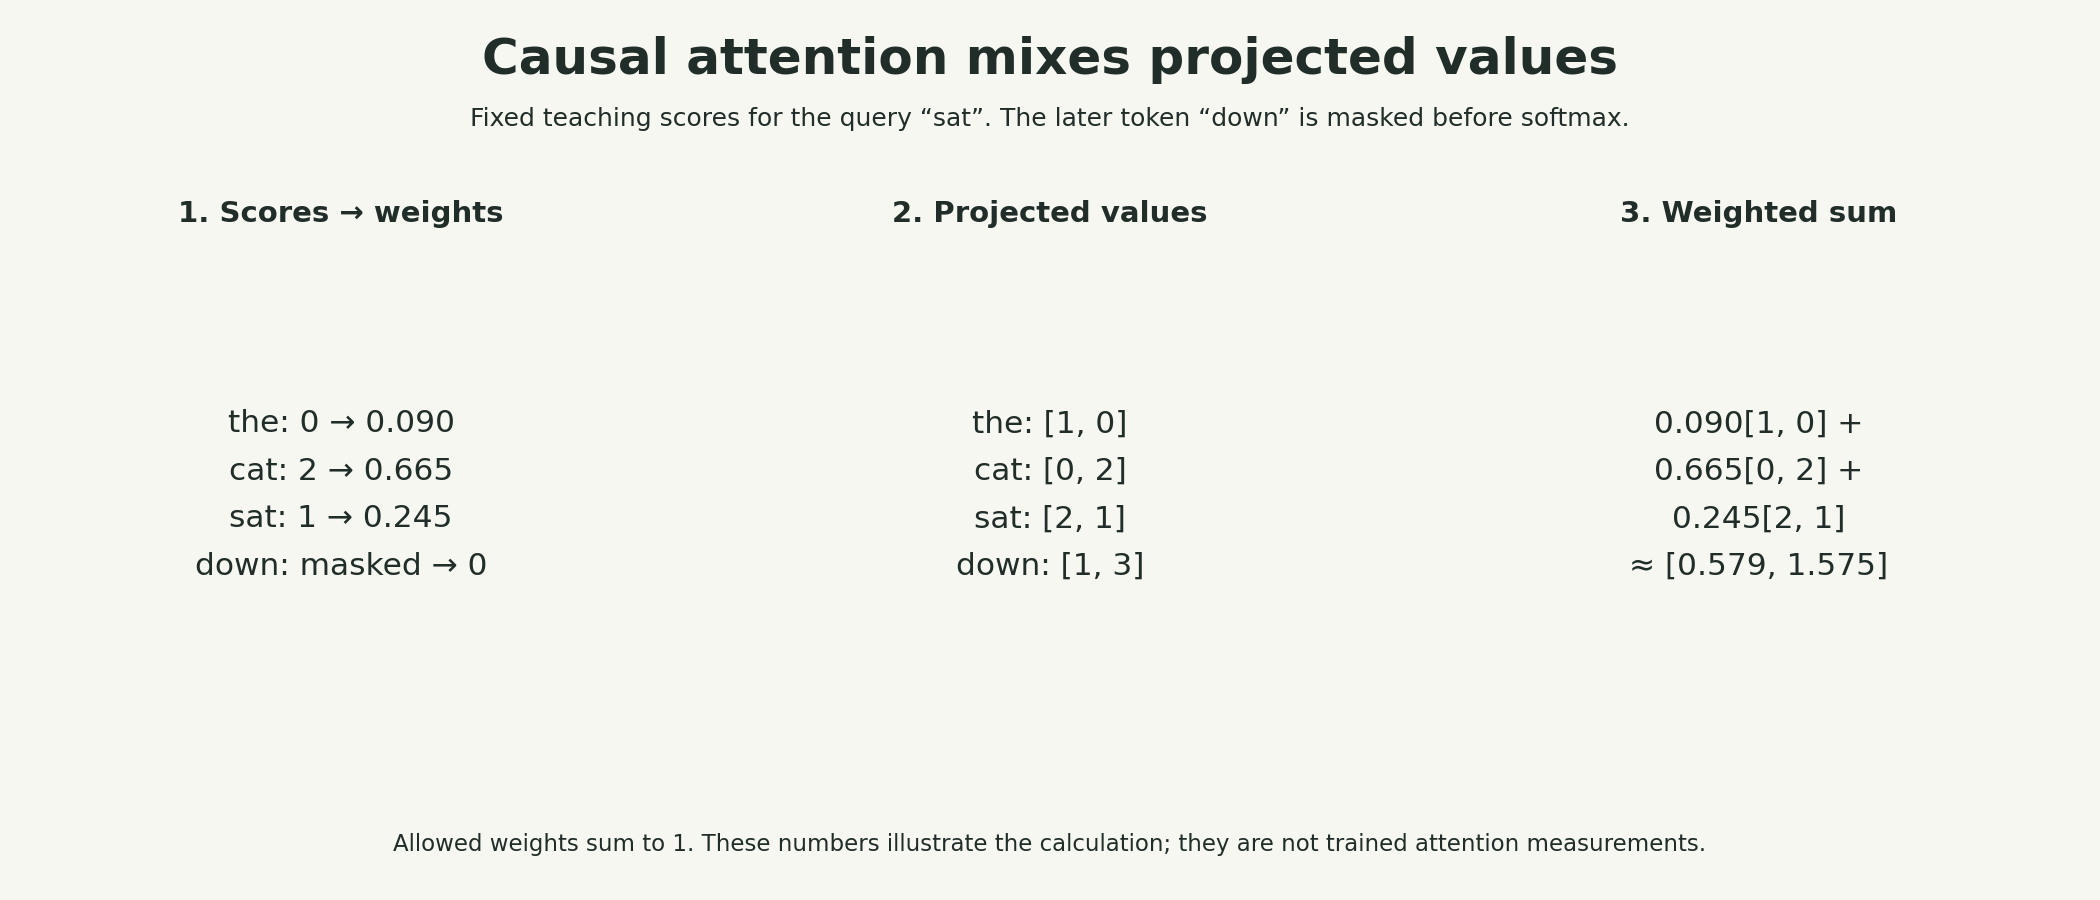

*These supplied numbers illustrate the calculation. The web app adds a paused, step-by-step animation of the same example.*

## 8. Causal Attention vs. Bidirectional Attention

So far, every token could attend to every other token, including the ones after it. That is **bidirectional** attention, used in encoders. A decoder that generates text must not let a token see the future, because during generation the future has not been written yet. If it could peek during training, it would learn to "predict" the next token by simply reading it, and would fail completely when generating.

The fix is the **causal mask** from Note 6.1. Before softmax, we replace every score where the key comes *after* the query with −∞ (minus infinity). Since e to the power of −∞ is 0, softmax gives those positions exactly zero weight, and the remaining weights still add up to 1.

In [9]:
T = 4
causal = torch.tril(torch.ones(T, T, dtype=torch.bool))       # True = allowed
masked_scores = scores.masked_fill(~causal, float("-inf"))      # forbidden positions get -infinity
causal_weights = torch.softmax(masked_scores, dim=-1)
print("masked scores:\n", masked_scores.round(decimals=3))
print("causal attention weights:\n", causal_weights.round(decimals=3))
print("row sums:", causal_weights.sum(-1).tolist())

masked scores:
 tensor([[0.7070,   -inf,   -inf,   -inf],
        [0.7070, 0.0000,   -inf,   -inf],
        [0.0000, 2.8280, 0.7070,   -inf],
        [0.3540, 2.8280, 0.8840, 0.1770]])
causal attention weights:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.6700, 0.3300, 0.0000, 0.0000],
        [0.0500, 0.8480, 0.1020, 0.0000],
        [0.0650, 0.7710, 0.1100, 0.0540]])
row sums: [1.0, 1.0, 1.0, 1.0]


The masked score grid has −∞ above the diagonal, and the weights there are exactly 0. Each row still sums to 1. Notice how the rows change:

- "the" (position 0) can only see itself, so it gives itself all of its attention: 1.000.
- "cat" (position 1) can see "the" and itself: 0.670 and 0.330.
- "sat" (position 2) still gives most attention to "cat" (0.848), because "cat" comes before it.
- "down" (position 3) can see everything, so its row is unchanged from the unmasked version.

> **Key terms**
> - **Self-attention:** attention in which a sequence's tokens attend to tokens of the same sequence.
> - **Query, key, value:** three learned projections of each token: what it looks for, how it is matched, and what it passes on.
> - **Attention score:** the dot product of a query with a key, divided by √d.
> - **Attention weights:** the softmax of the scores; each token's weights sum to 1.
> - **Causal mask:** setting scores for future positions to −∞ so their weights become 0.

**Check yourself.**

1. In a causal model, how many tokens can position 0 attend to, and what is its weight on each?

<details>
<summary>Worked answer</summary>

One: itself. With only one allowed position, softmax gives it a weight of 1.

</details>

## 9. Multi-Head Attention

A single attention pattern can only express one kind of relevance at a time. But a token often needs several kinds of information at once: the previous word, the subject of the sentence, an earlier mention of the same name, the matching opening bracket. **Multi-head attention** runs several attention operations, called **heads**, side by side, each with its own query, key and value projections, so that each can learn a different kind of relationship.

To keep the cost the same, the model's vector is **split** between the heads rather than copied. With `d_model = 64` and 4 heads, each head works with 16 numbers:

In [10]:
d_model, n_heads = 64, 4
d_head = d_model // n_heads
xb = torch.randn(1, 10, d_model)                                   # (batch, T, d_model)
heads = xb.view(1, 10, n_heads, d_head).transpose(1, 2)            # (batch, heads, T, d_head)
print("d_model", d_model, "split into", n_heads, "heads of", d_head)
print("before split:", tuple(xb.shape), "-> per-head view:", tuple(heads.shape))
merged = heads.transpose(1, 2).reshape(1, 10, d_model)
print("merged back:", tuple(merged.shape), "| identical to the original?", torch.equal(merged, xb))

d_model 64 split into 4 heads of 16
before split: (1, 10, 64) -> per-head view: (1, 4, 10, 16)
merged back: (1, 10, 64) | identical to the original? True


A `(1, 10, 64)` tensor is viewed as `(1, 4, 10, 16)`: 4 heads, each seeing all 10 tokens with 16 numbers per token. Each head computes its own `(10, 10)` grid of weights. Afterwards, the heads' outputs are put back side by side into `(1, 10, 64)`, and a final linear layer combines them. Reshaping back and forth loses nothing (`True`).

To see why several heads help, let's build two heads **by hand**, each designed to capture a different relationship, for the words "to be or not to be". Each token's input vector contains two parts: which word it is, and which position it is at. We set the query and key weights directly:

- **Head A** turns each token's *position* into a query for the **previous** position.
- **Head B** turns each token's *word* into a query for the **same word**.

In [11]:
words = ["to", "be", "or", "not", "to", "be"]
uniq = sorted(set(words)); T = len(words)
tok_onehot = F.one_hot(torch.tensor([uniq.index(w) for w in words]), len(uniq)).float()   # (6, 4)
pos_onehot = torch.eye(T)                                                                 # (6, 6)
x = torch.cat([tok_onehot, pos_onehot], dim=1)                                            # (6, 10) input vectors
print("input vectors:", tuple(x.shape))
# Head A: "look at the previous position". Query = my position shifted back by one; key = position.
Wq_A = torch.zeros(10, T); Wk_A = torch.zeros(10, T)
for p in range(1, T): Wq_A[len(uniq) + p, p - 1] = 5.0
for p in range(T): Wk_A[len(uniq) + p, p] = 1.0
# Head B: "look at earlier copies of my own word". Query = key = token identity.
Wq_B = torch.zeros(10, len(uniq)); Wk_B = torch.zeros(10, len(uniq))
for t in range(len(uniq)): Wq_B[t, t] = 5.0; Wk_B[t, t] = 1.0
mask = torch.tril(torch.ones(T, T, dtype=torch.bool))
def head_weights(Wq, Wk):
    s = (x @ Wq) @ (x @ Wk).T
    return torch.softmax(s.masked_fill(~mask, float("-inf")), dim=-1)
wA, wB = head_weights(Wq_A, Wk_A), head_weights(Wq_B, Wk_B)
print("head A, row for position 3 ('not'):", [round(v, 3) for v in wA[3].tolist()])
print("head B, row for position 5 ('be'): ", [round(v, 3) for v in wB[5].tolist()])

input vectors: (6, 10)
head A, row for position 3 ('not'): [0.007, 0.007, 0.98, 0.007, 0.0, 0.0]
head B, row for position 5 ('be'):  [0.003, 0.493, 0.003, 0.003, 0.003, 0.493]


The rows confirm the designs. Head A's row for "not" (position 3) puts 0.98 of its weight on position 2, the previous word "or". Head B's row for the second "be" (position 5) splits its weight between itself and the earlier "be" at position 1, 0.493 each: it found the previous copy of its own word. Here are both heads as heatmaps:

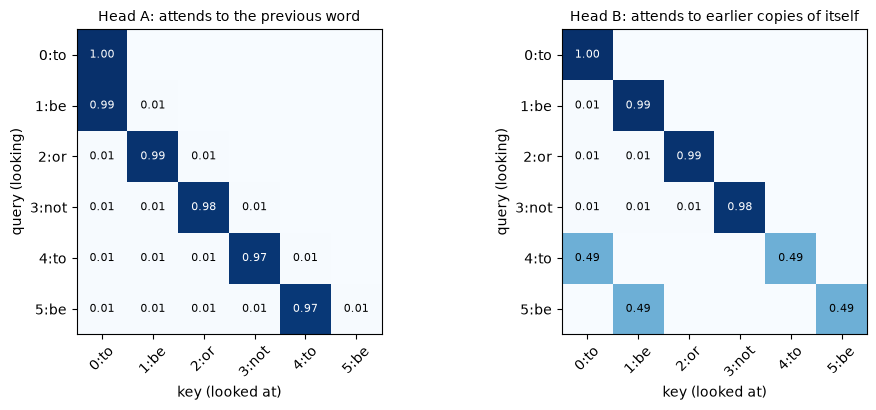

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, w, title in [(axes[0], wA, "Head A: attends to the previous word"),
                     (axes[1], wB, "Head B: attends to earlier copies of itself")]:
    ax.imshow(w, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(T), [f"{p}:{w_}" for p, w_ in enumerate(words)], rotation=45)
    ax.set_yticks(range(T), [f"{p}:{w_}" for p, w_ in enumerate(words)])
    for r in range(T):
        for c in range(T):
            if w[r, c] > 0.005: ax.text(c, r, f"{w[r, c]:.2f}", ha="center", va="center", fontsize=8,
                                        color="white" if w[r, c] > 0.5 else "black")
    ax.set_title(title, fontsize=10); ax.set_xlabel("key (looked at)"); ax.set_ylabel("query (looking)")
plt.tight_layout(); plt.show()

Head A forms a clear diagonal one step below the main diagonal: every token looks at its predecessor (the first token, having no predecessor, looks at itself). Head B lights up only where a word matches an earlier copy of itself. The two heads read the same sentence and gather completely different information, and the model receives both.

In a real Transformer, nobody designs the heads. Their weights are learned, and trained models do develop specialised heads like these. Patterns very much like Head A, "attend to the previous token", are among the most commonly found in trained language models. We will look at the heads of our own trained model in Note 6.6.

> **Key terms**
> - **Head:** one attention operation with its own query, key and value projections.
> - **Multi-head attention:** several heads running in parallel on slices of the model vector, combined by a final linear layer.
> - **`d_head`:** the vector length per head, `d_model / n_heads`.

**Check yourself.**

1. A model has `d_model = 512` and 8 heads. What is `d_head`?

<details>
<summary>Worked answer</summary>

512 / 8 = 64.

</details>

## 10. Attention Is Order-Blind: Positional Information

Look back at the formula in Section 3. Nothing in it refers to *where* a token sits. Scores depend only on the vectors themselves. So if you shuffle the input tokens, every token still finds exactly the same partners with exactly the same weights, and the outputs are simply shuffled in the same way. Let's verify that with PyTorch's own attention layer:

In [13]:
torch.manual_seed(0)
attn = nn.MultiheadAttention(embed_dim=16, num_heads=2, batch_first=True)
seq = torch.randn(1, 5, 16)
perm = torch.tensor([3, 0, 4, 1, 2])                                # shuffle the 5 tokens
with torch.no_grad():
    out_a, _ = attn(seq, seq, seq)
    out_b, _ = attn(seq[:, perm], seq[:, perm], seq[:, perm])
print("shuffled input gives the same outputs, just shuffled?", torch.allclose(out_a[:, perm], out_b, atol=1e-6))
pos = torch.randn(1, 5, 16)                                         # one vector per POSITION
with torch.no_grad():
    out_c, _ = attn(seq + pos, seq + pos, seq + pos)
    sp = seq[:, perm] + pos                                          # tokens move, positions stay
    out_d, _ = attn(sp, sp, sp)
print("with position vectors added, still just shuffled?", torch.allclose(out_c[:, perm], out_d, atol=1e-6))

shuffled input gives the same outputs, just shuffled? True
with position vectors added, still just shuffled? False


Without position information, shuffling the 5 input tokens gives exactly the same outputs, in the shuffled order (`True`). To attention alone, "dog bites man" and "man bites dog" would be the same bag of words, as in Note 5.4. But when we add a vector for each **position** before attention (and the positions stay put while the tokens move), shuffling the tokens changes the outputs (`False`). The position vectors have broken the symmetry: the model can now tell orderings apart.

Transformers generally supply position through learned vectors, sinusoidal encodings, or mechanisms inside attention such as RoPE. The causal mask also carries some ordering information, so the unmasked permutation argument does not apply unchanged to causal attention. There are two common ways:

- **Learned position embeddings:** a table with one learnable vector per position, as in Note 6.2. This is what our model uses.
- **Sinusoidal positional encodings:** fixed vectors made from sine and cosine waves of many different frequencies, as in the original Transformer. Each dimension oscillates at its own speed, so every position gets a unique pattern.

Let's compute the sinusoidal version for 64 positions and look at it.

sinusoidal table: (64, 64)
cosine of position 10 with positions 10, 11, 15, 30, 60: [1.0, 0.966, 0.734, 0.59, 0.49]


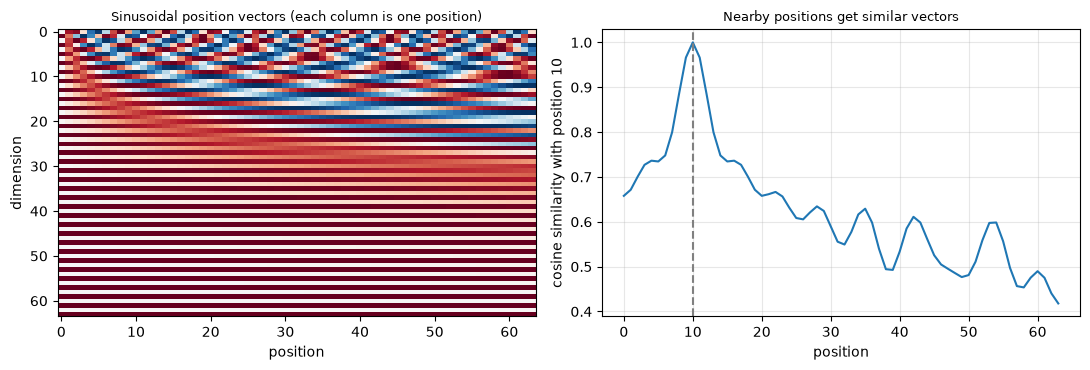

In [14]:
def sinusoidal(n_pos, d):
    pe = torch.zeros(n_pos, d)
    position = torch.arange(n_pos).unsqueeze(1).float()
    freq = torch.exp(-math.log(10000.0) * torch.arange(0, d, 2).float() / d)
    pe[:, 0::2] = torch.sin(position * freq)
    pe[:, 1::2] = torch.cos(position * freq)
    return pe
pe = sinusoidal(64, 64)
print("sinusoidal table:", tuple(pe.shape))
sim = F.normalize(pe, dim=1) @ F.normalize(pe, dim=1).T
print("cosine of position 10 with positions 10, 11, 15, 30, 60:",
      [round(sim[10, p].item(), 3) for p in [10, 11, 15, 30, 60]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].imshow(pe.T, cmap="RdBu_r", aspect="auto"); axes[0].set_xlabel("position"); axes[0].set_ylabel("dimension")
axes[0].set_title("Sinusoidal position vectors (each column is one position)", fontsize=9)
axes[1].plot(sim[10].numpy()); axes[1].axvline(10, color="grey", ls="--")
axes[1].set_xlabel("position"); axes[1].set_ylabel("cosine similarity with position 10")
axes[1].set_title("Nearby positions get similar vectors", fontsize=9); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In the left panel, each column is one position's 64-number vector. The top dimensions oscillate quickly from position to position, and the lower ones slowly, rather like the hands of a clock: the second hand tells you small differences, the hour hand large ones. Together they give every position a distinct pattern.

The right panel shows a useful property: nearby positions get similar vectors. The cosine similarity of position 10 with itself is 1.0, with position 11 it is 0.966, with position 15 it is 0.734, and it tends to fall further with distance (0.59 at position 30, 0.49 at position 60), although not perfectly smoothly. So the encoding carries a sense of "near" and "far", which attention can use.

> **Common mistake:** forgetting positional information when building a Transformer from scratch. The model will still train, but unmasked attention is permutation-equivariant, while causal attention has only the ordering information supplied by its mask, and it will plateau at a much worse loss than it should.

**Check yourself.**

1. If attention by itself ignores order, why does a decoder with a causal mask still know *something* about order, even without position vectors? (Hint: think about what each position is allowed to see.)

<details>
<summary>Worked answer</summary>

The causal mask itself carries some order information: position 0 can attend only to one token, position 1 to two tokens, and so on. A token can partly infer where it is from how many tokens it can see. This is weak and indirect, so models still add explicit positional information.

</details>

## 11. The Cost of Attention: Why It Grows with Sequence Length Squared

Attention's great strength, that every token compares itself with every other token, is also its main cost. With T tokens, each head computes a T × T grid of scores. Double the sequence length and that grid becomes four times larger.

In [15]:
print(f"{'tokens T':>9} {'scores per head (T x T)':>24} {'float32 memory, 1 head':>23} {'vs. T=64':>10}")
for T_ in [64, 1024, 8192, 131072]:
    entries = T_ * T_
    mem = entries * 4
    mem_s = f"{mem / 2**10:,.0f} KB" if mem < 2**20 else f"{mem / 2**20:,.0f} MB"
    print(f"{T_:>9,} {entries:>24,} {mem_s:>23} {entries // 64**2:>9,}x")

 tokens T  scores per head (T x T)  float32 memory, 1 head   vs. T=64
       64                    4,096                   16 KB         1x
    1,024                1,048,576                    4 MB       256x
    8,192               67,108,864                  256 MB    16,384x
  131,072           17,179,869,184               65,536 MB 4,194,304x


With our context of 64 tokens, each head's score grid has 4,096 entries and needs 16 KB of memory at 32-bit precision. At 1,024 tokens it has 1,048,576 entries (4 MB): 256 times as many as at 64. At 8,192 tokens it needs 256 MB, per head, per layer, per sequence. At 131,072 tokens a single grid would need 65,536 MB, 64 GB, more memory than most GPUs have, and that is for just one head of one layer.

This **quadratic cost** is the main reason context windows were limited for many years, and a great deal of engineering goes into managing it. Two key ideas are worth knowing by name:

- **Memory-efficient attention** (for example FlashAttention) computes the same result in small tiles without ever storing the full T × T grid. PyTorch's `F.scaled_dot_product_attention`, which you will use in Section 12, can use such methods automatically.
- **Restricted attention patterns** let each token attend to only part of the sequence, such as a sliding window of recent tokens, trading some reach for a cost that grows more slowly.

**Check yourself.**

1. A model's context is increased from 4,096 to 16,384 tokens. By what factor does the size of each attention score grid grow?

<details>
<summary>Worked answer</summary>

16,384 / 4,096 = 4 times as many tokens, so 4² = 16 times as many entries in each score grid.

</details>

## 12. Implementing Scaled Dot-Product Attention with PyTorch

Now we can put everything together into the attention module that our model will use in Note 6.5. It takes a batch of shape `(B, T, d_model)` and returns the same shape. Read the comments beside each line for the shapes.

- **One linear layer** produces queries, keys and values at once (`3 * d_model` outputs), which we split into three.
- **`view` and `transpose`** split the model vector into heads: `(B, T, D)` becomes `(B, H, T, d_head)`.
- **The core** is the formula from Section 3: scores, scaling, causal mask, softmax, weighted sum of values. All heads are computed at once, because the head dimension is treated just like the batch dimension.
- **Merge and project:** the heads are put back side by side, and the output projection `proj` combines them.

In [16]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.d_head = n_heads, d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)     # queries, keys and values in one matrix multiply
        self.proj = nn.Linear(d_model, d_model)        # combines the heads' outputs
    def forward(self, x, return_weights=False):
        B, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)                                  # each (B, T, D)
        q, k, v = [t.view(B, T, self.n_heads, self.d_head).transpose(1, 2) for t in (q, k, v)]  # (B, H, T, d_head)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.d_head)              # (B, H, T, T)
        mask = torch.tril(torch.ones(T, T, dtype=torch.bool, device=x.device))
        weights = torch.softmax(scores.masked_fill(~mask, float("-inf")), dim=-1)
        out = (weights @ v).transpose(1, 2).reshape(B, T, D)                   # (B, T, D): heads merged
        out = self.proj(out)
        return (out, weights) if return_weights else out

torch.manual_seed(0)
csa = CausalSelfAttention(64, 4)
x = torch.randn(2, 12, 64)
y, w = csa(x, return_weights=True)
print("input:", tuple(x.shape), "| output:", tuple(y.shape), "| weights:", tuple(w.shape))
print("parameters:", sum(p.numel() for p in csa.parameters()))

input: (2, 12, 64) | output: (2, 12, 64) | weights: (2, 4, 12, 12)
parameters: 16640


Input and output are both `(2, 12, 64)`, and the weights have shape `(2, 4, 12, 12)`: for each of 2 sequences and 4 heads, a 12 × 12 grid. The module has 16,640 parameters: 64 × 192 + 192 for the combined query–key–value layer, plus 64 × 64 + 64 for the output projection.

Any implementation from scratch should be checked against a trusted one. PyTorch provides `F.scaled_dot_product_attention`, which computes the core of attention (in a fast, memory-efficient way) given queries, keys and values. We feed it the same queries, keys and values as our module and compare:

In [17]:
with torch.no_grad():
    q, k, v = csa.qkv(x).split(64, dim=2)
    q, k, v = [t.view(2, 12, 4, 16).transpose(1, 2) for t in (q, k, v)]
    ref = F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(2, 12, 64)
    ref = csa.proj(ref)
print("matches PyTorch's scaled_dot_product_attention?", torch.allclose(y, ref, atol=1e-5))
print("max difference:", f"{(y - ref).abs().max().item():.1e}")
print("no weight above the diagonal?", bool((w.triu(1) == 0).all()))

matches PyTorch's scaled_dot_product_attention? True
max difference: 1.2e-07
no weight above the diagonal? True


Our implementation matches PyTorch's (`True`), with a maximum difference of 1.2e-07, which is just floating-point rounding. And no weight sits above the diagonal (`True`), so the causal mask works. In real projects you would normally call `F.scaled_dot_product_attention` directly, because it is faster and uses less memory; writing it yourself once is how you understand what it does.

Finally, let's look at the weights our untrained module produces for the opening of Romeo's famous line, `"ROMEO:\nBut, soft! what light"`, using random untrained embeddings.

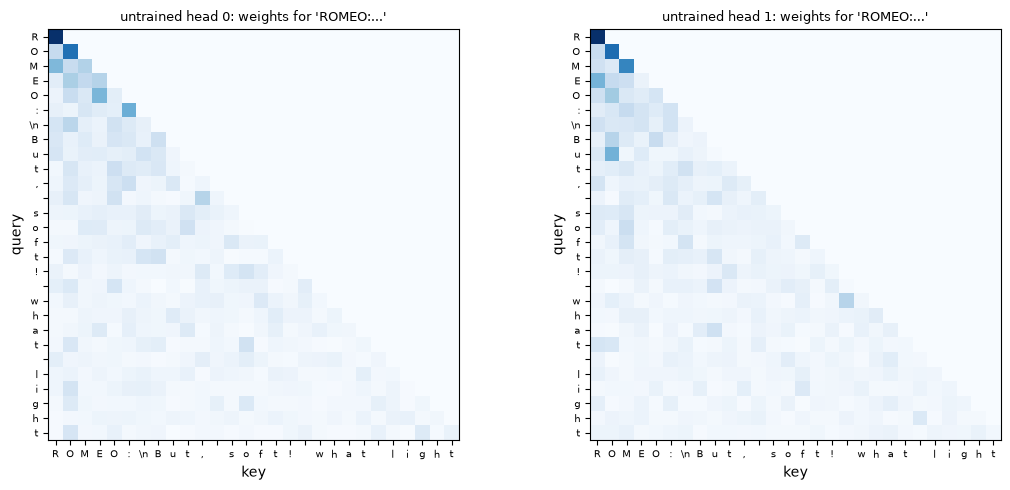

last position, head 0: largest weight 0.168 | uniform over 28 positions would be 0.036


In [18]:
line = "ROMEO:\nBut, soft! what light"
cs = sorted(set(line)); ids = torch.tensor([[cs.index(c) for c in line]])
torch.manual_seed(0)
toy_emb, toy_pos = nn.Embedding(len(cs), 64), nn.Embedding(len(line), 64)
with torch.no_grad():
    _, w = csa(toy_emb(ids) + toy_pos(torch.arange(len(line))), return_weights=True)
labels = [repr(c)[1:-1] for c in line]
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for h, ax in enumerate(axes):
    ax.imshow(w[0, h], cmap="Blues"); ax.set_title(f"untrained head {h}: weights for '{line[:6]}...'", fontsize=9)
    ax.set_xticks(range(len(line)), labels, fontsize=7); ax.set_yticks(range(len(line)), labels, fontsize=7)
    ax.set_xlabel("key"); ax.set_ylabel("query")
plt.tight_layout(); plt.show()
row = w[0, 0, -1]
print(f"last position, head 0: largest weight {row.max():.3f} | uniform over {len(line)} positions would be {1 / len(line):.3f}")

The triangle shape is the causal mask at work: nothing above the diagonal. Within the triangle, the patterns are noisy and unfocused. For the last position, head 0's largest weight is 0.168, compared with 0.036 if the weight were spread evenly over all 28 positions. There is some structure, from the random weights, but nothing meaningful: an untrained module has not yet learned what to look for. In Note 6.6 we will draw the same kind of picture for the trained model and compare.

## Putting It All Together

Layers that process each token on its own cannot build context: "bank" gave identical outputs in two different sentences. **Self-attention** fixes this in three steps: compare, normalise, average.

Each token produces a **query** (what it looks for), a **key** (how it is matched) and a **value** (what it passes on). Scores are query–key dot products, **divided by √d**, because otherwise their spread grows with the vector size (22.45 at d = 512) and softmax collapses onto one key (weight 1.000, entropy 0.000). **Softmax** turns each token's scores into weights that sum to 1, and each output is the **weighted average of the values**. In our example, "sat" put 0.808 of its attention on "cat" and came out mostly "cat". A **causal mask** sets future scores to −∞, so decoders never see ahead.

**Multi-head attention** splits the vector among several heads, each free to capture a different relationship, such as "previous word" or "earlier copy of me". Because attention alone ignores order, we add **positional information**, learned or sinusoidal. Attention's power has a price: each head's score grid grows with T², from 16 KB at 64 tokens to 64 GB at 131,072.

Our `CausalSelfAttention` module, with 16,640 parameters, matches PyTorch's `scaled_dot_product_attention` to within 1.2e-07. It is the attention layer we will use in our model.

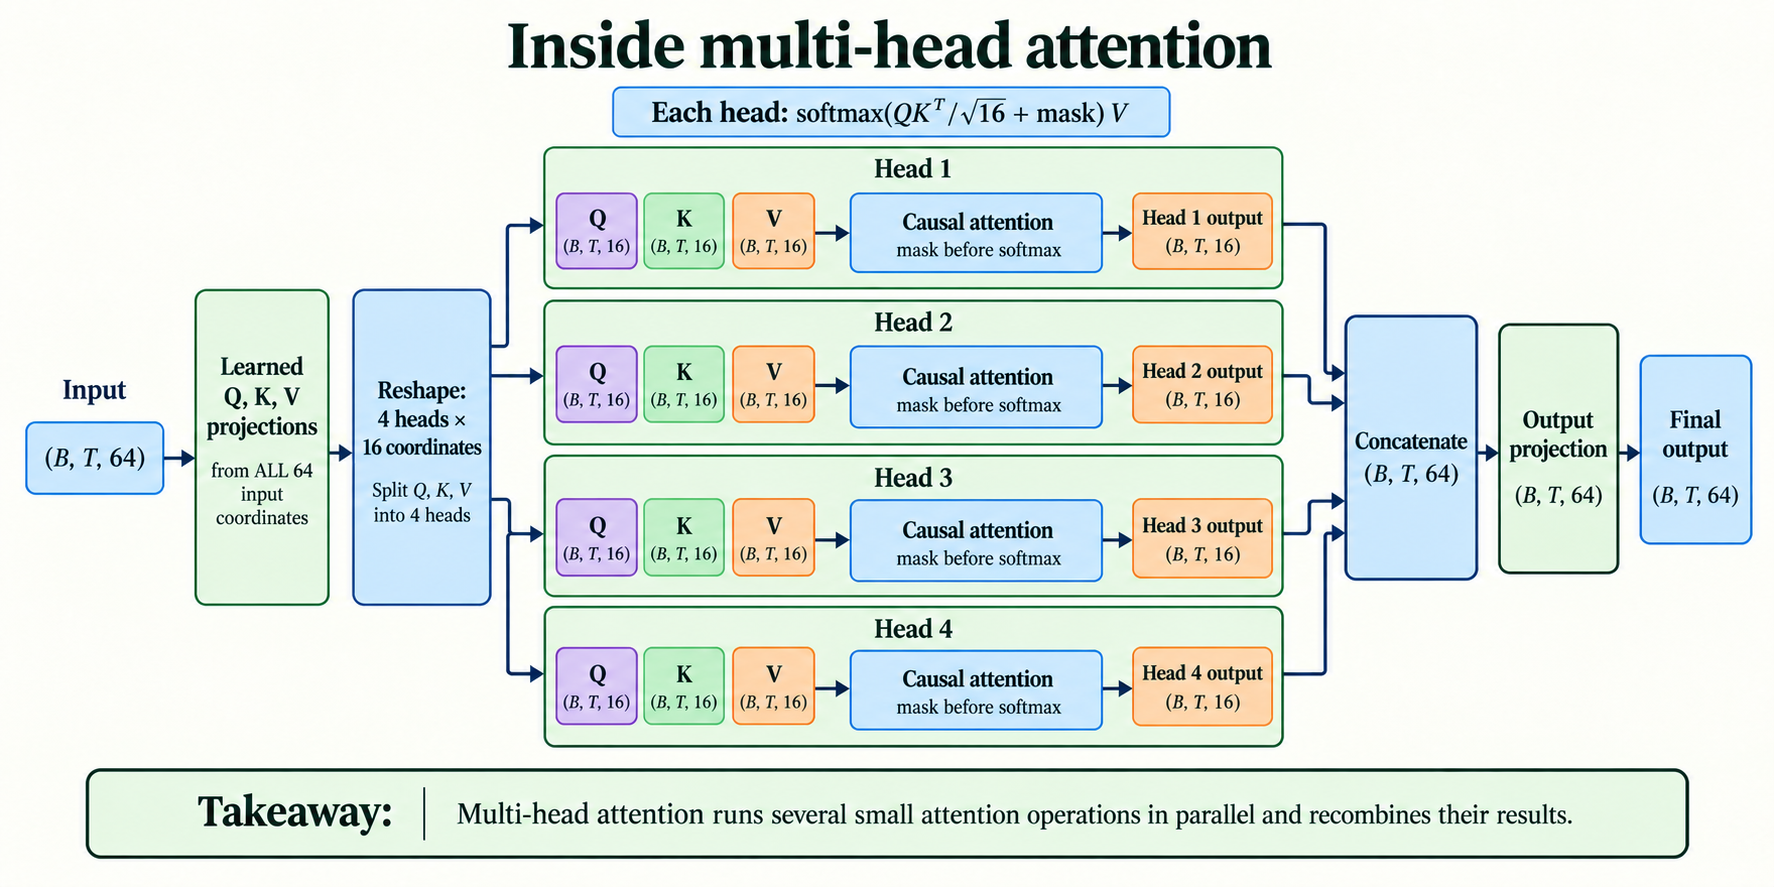

*Figure 6.3.3. Learn Q, K and V from the full 64-coordinate input, then reshape into four 16-coordinate heads. Concatenate their outputs and apply an output projection. Heads do not receive disjoint slices of the original unprojected input.*

## Summary

- Per-token layers cannot build context; attention is the mechanism that lets tokens read from each other.
- Each token gets a **query**, **key** and **value** from learned linear layers. Scores are dot products of queries with keys.
- Attention(Q, K, V) = softmax(QKᵀ / √d) V: compare, scale, normalise, average.
- Dividing by **√d** keeps scores at a stable size; without it, softmax saturates on a single key and gradients vanish.
- Each token's output is a relevance-weighted average of value vectors: a contextual representation.
- A **causal mask** (−∞ before softmax) stops tokens attending to the future.
- **Multi-head attention** splits the vector into several heads that can capture different relationships, then recombines them.
- Attention is **order-blind**, so Transformers add learned or sinusoidal **positional information**.
- Each head's score grid has T² entries, so attention's cost grows **quadratically** with sequence length.

## Glossary

| Term | Meaning |
|---|---|
| Self-attention | Attention among the tokens of one sequence. |
| Query / key / value | Learned projections: what a token looks for, how it is matched, what it passes on. |
| Attention score | Query · key / √d for a pair of tokens. |
| Scaling (√d) | Dividing scores by the square root of the vector length to keep their size stable. |
| Softmax | Turns scores into positive weights that sum to 1. |
| Attention weights | The softmaxed scores; how much each token attends to each other token. |
| Weighted sum | The output: attention weights multiplied by values. |
| Causal mask | Setting future scores to −∞ so they get zero weight. |
| Bidirectional attention | Attention in which every token may see every other token. |
| Head | One attention operation with its own projections. |
| Multi-head attention | Several heads in parallel, concatenated and projected. |
| Permutation equivariance | Permuting the input tokens permutes the output vectors in the same way, for unmasked attention without positional information. |
| Position embedding / encoding | Learned / fixed vectors that tell the model each token's position. |
| Sinusoidal encoding | Position vectors made of sine and cosine waves at many frequencies. |
| Quadratic cost | Cost that grows with the square of the sequence length. |
| `scaled_dot_product_attention` | PyTorch's fast built-in function for the core of attention. |